# Later commits that reference AI PRs
**Paper:** Khemissi et al. 2026 – Humans Integrate, Agents Fix (arXiv 2604.04059)
**Data:** Figshare https://figshare.com/s/e750940213ea9df98867 (folder `replication_package_v2`)

**What is in the data:** From AIDev-pop timelines: **commits that reference an earlier agent PR**. 1,922 references from **human** commits and 88 from **agent** PRs, with the commit message and the **code patch** of the referencing commit. A sample (124 + 88) was labelled by hand: add, **fix**, update, revert…

**One row of the main table =** one reference: later commit → agent PR

This notebook has 3 parts:
1. **First look** – the files, some lines, all the columns, the size.
2. **Data-science view** – size, dates, **numbers per AI agent**, **how the agent is involved** (tables saved in `tables/`).
3. **Charts** – what kind of change · fixes per AI agent · who wrote the fix · how fast the fix comes · extra (saved in `charts/`).

In [1]:
import sys, os, json
sys.path.insert(0, "..")          # to find common.py in the parent folder
from common import *

## 0. Get the data
Downloaded by hand from Figshare into `Paper_Datasets/replication_package_v2` (the 946 MB `commits_data.csv` is not needed).

In [2]:
DATA = None
for cand in [os.path.join(DATA_DIR, "replication_package_v2"), os.path.join("..", "replication_package_v2"), "replication_package_v2"]:
    if os.path.exists(cand): DATA = cand; break
assert DATA, "Put the folder 'replication_package_v2' in data/" + os.path.basename(os.getcwd())
print("Data folder:", DATA)

Data folder: ../../data/09_Khemissi_References/replication_package_v2


## 1. First look
### Files

In [3]:
list_files(DATA)

,file,size_MB
0,results/05_human_references_with_co_authors.csv,15.31
1,results/01_data_agent_to_agent.csv,1.11
2,manual_verification/manual_human_references_cleaned.csv,0.18
3,manual_verification/manual_pr_references_urls_with_agent...,0.04
4,results/time_to_decision_summary_table.csv,0.00


### Table 1 (main): human commits that reference an agent PR (+ agent co-author)

In [4]:
h = pd.read_csv(os.path.join(DATA, "results", "05_human_references_with_co_authors.csv"), low_memory=False)
_ = overview(h.drop(columns=["target_pr_body", "source_pr_body", "source_commit_patch"]), "Human → agent references")

**Human → agent references** — **1,922 rows × 54 columns** (7.5 MB in memory)

*First 5 lines:*

,target_pr_created_at,target_pr_created_at.1,target_pr_id,target_pr_number,target_pr_title,target_pr_agent,target_pr_user_id,target_pr_user,target_pr_state,target_pr_created_at.2,target_pr_created_at.3,target_pr_closed_at,target_pr_merged_at,target_pr_repo_id,target_pr_repo_url,target_pr_html_url,target_pr_repo_html,pr_id,event,commit_id,actor,assignee,label,message,source_commit_sha,...,source_commit_commit_stats_total,source_commit_commit_stats_additions,source_commit_commit_stats_deletions,filename,source_commit_status,source_commit_additions,source_commit_deletions,source_commit_changes,source_commit_target_pr_rpatchepo_html,source_pr_id,source_pr_number,source_pr_title,source_pr_agent,source_pr_user_id,source_pr_user,source_pr_state,source_pr_created_at,source_pr_closed_at,source_pr_merged_at,source_pr_repo_id,source_pr_repo_url,source_pr_html_url,source_pr_repo_html,source_commit_filename,source_commit_co_author
0,2025-06-22T00:39:15Z,2025-06-20T12:55:27Z,3163243464,128,fix: add offline flag support to blocks command,Claude_Code,4208883,zhiyue,closed,2025-06-22T00:39:15Z,2025-06-20T12:55:27Z,2025-06-20T13:24:12Z,2025-06-20T13:24:11Z,9.927551e+08,https://api.github.com/repos/ryoppippi/ccusage,https://github.com/ryoppippi/ccusage/pull/128,https://github.com/ryoppippi/ccusage,3163243464,referenced,c2e44b65d379e9de5ac65bc758b35be1283f03ec,ryoppippi,NaN,NaN,NaN,c2e44b65d379e9de5ac65bc758b35be1283f03ec,...,3.0,2.0,1.0,NaN,modified,1.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,src/data-loader.ts,NaN
1,2025-07-29T08:14:33Z,2025-07-29T06:22:16Z,3272275087,114,feat: Add tag support for API Keys and fix OAuth token e...,Claude_Code,9427550,Alfonsxh,closed,2025-07-29T08:14:33Z,2025-07-29T06:22:16Z,2025-07-29T08:19:53Z,NaN,1.019433e+09,https://api.github.com/repos/Wei-Shaw/claude-relay-service,https://github.com/Wei-Shaw/claude-relay-service/pull/114,https://github.com/Wei-Shaw/claude-relay-service,3272275087,referenced,03a5300b78c45bbc4bee7323584aa28c9c89ecdb,Wei-Shaw,NaN,NaN,NaN,03a5300b78c45bbc4bee7323584aa28c9c89ecdb,...,214.0,202.0,12.0,NaN,modified,44.0,2.0,46.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,web/admin-spa/src/views/ApiKeysView.vue,Claude_Code
2,2025-08-04T06:34:29Z,2025-07-29T06:22:16Z,3272275087,114,feat: Add tag support for API Keys and fix OAuth token e...,Claude_Code,9427550,Alfonsxh,closed,2025-08-04T06:34:29Z,2025-07-29T06:22:16Z,2025-07-29T08:19:53Z,NaN,1.019433e+09,https://api.github.com/repos/Wei-Shaw/claude-relay-service,https://github.com/Wei-Shaw/claude-relay-service/pull/114,https://github.com/Wei-Shaw/claude-relay-service,3272275087,referenced,1b9f945c3b44dae884017282ec89777cabffac68,mouyong,NaN,NaN,NaN,1b9f945c3b44dae884017282ec89777cabffac68,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025-07-24T11:20:53Z,2025-07-19T09:48:04Z,3245161961,706,feat(gfql): PR 1.2 - Basic Working DAG execution,Claude_Code,4249447,lmeyerov,closed,2025-07-24T11:20:53Z,2025-07-19T09:48:04Z,2025-07-28T07:42:13Z,NaN,3.675991e+07,https://api.github.com/repos/graphistry/pygraphistry,https://github.com/graphistry/pygraphistry/pull/706,https://github.com/graphistry/pygraphistry,3245161961,referenced,702599939f392c41a38a3a4aea7af276fabab159,lmeyerov,NaN,NaN,NaN,702599939f392c41a38a3a4aea7af276fabab159,...,18.0,9.0,9.0,NaN,modified,2.0,2.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,graphistry/tests/compute/test_call_operations_gpu.py,Claude_Code
4,2025-07-04T00:39:35Z,2025-06-22T02:21:35Z,3165597086,80,Implement automated demo recording CI/CD pipeline (close...,Claude_Code,80381,sugyan,closed,2025-07-04T00:39:35Z,2025-06-22T02:21:35Z,2025-06-22T13:55:42Z,2025-06-22T13:55:42Z,9.992860e+08,https://api.github.com/repos/sugyan/claude-code-webui,https://github.com/sugyan/claude-code-webui/pull/80,https://github.com/sugyan/claude-code-webui,3165597086,referenced,c34450b5fabfb832ca88c6cb711397308ee23f70,sugyan,NaN,

*All columns:*

,column,type,missing_%,unique,example
0,target_pr_created_at,str,0.0,1229,2025-06-22T00:39:15Z
1,target_pr_created_at.1,str,0.0,1388,2025-06-20T12:55:27Z
2,target_pr_id,int64,0.0,1388,3163243464
3,target_pr_number,int64,0.0,1228,128
4,target_pr_title,str,0.0,1378,fix: add offline flag support to blocks command
5,target_pr_agent,str,0.0,5,Claude_Code
6,target_pr_user_id,int64,0.0,255,4208883
7,target_pr_user,str,0.0,255,zhiyue
8,target_pr_state,str,0.0,2,closed
9,target_pr_created_at.2,str,0.0,1229,2025-06-22T00:39:15Z


### Table 2: agent PRs that reference another agent PR

In [5]:
a = pd.read_csv(os.path.join(DATA, "results", "01_data_agent_to_agent.csv"), low_memory=False)
_ = overview(a.drop(columns=["target_pr_body", "source_pr_body"]), "Agent → agent references")

**Agent → agent references** — **88 rows × 52 columns** (0.9 MB in memory)

*First 5 lines:*

,target_pr_created_at,target_pr_created_at.1,target_pr_id,target_pr_number,target_pr_title,target_pr_agent,target_pr_user_id,target_pr_user,target_pr_state,target_pr_created_at.2,target_pr_created_at.3,target_pr_closed_at,target_pr_merged_at,target_pr_repo_id,target_pr_repo_url,target_pr_html_url,target_pr_repo_html,pr_id,event,commit_id,actor,assignee,label,message,source_commit_sha,...,source_commit_committer,source_commit_message,source_commit_commit_stats_total,source_commit_commit_stats_additions,source_commit_commit_stats_deletions,filename,source_commit_status,source_commit_additions,source_commit_deletions,source_commit_changes,source_commit_target_pr_rpatchepo_html,source_pr_id,source_pr_number,source_pr_title,source_pr_agent,source_pr_user_id,source_pr_user,source_pr_state,source_pr_created_at,source_pr_closed_at,source_pr_merged_at,source_pr_repo_id,source_pr_repo_url,source_pr_html_url,source_pr_repo_html
0,2025-07-04T00:32:54Z,2025-06-22T02:21:35Z,3165597086,80,Implement automated demo recording CI/CD pipeline (close...,Claude_Code,80381,sugyan,closed,2025-07-04T00:32:54Z,2025-06-22T02:21:35Z,2025-06-22T13:55:42Z,2025-06-22T13:55:42Z,999285986.0,https://api.github.com/repos/sugyan/claude-code-webui,https://github.com/sugyan/claude-code-webui/pull/80,https://github.com/sugyan/claude-code-webui,3165597086,referenced,037cc75189cba847cbe6aba10fd29df7a8b4505d,sugyan,NaN,NaN,NaN,037cc75189cba847cbe6aba10fd29df7a8b4505d,...,sugyan,fix: replace FedericoCarboni/setup-ffmpeg with apt-get i...,9.0,4.0,5.0,.github/workflows/demo-comparison.yml,modified,4.0,5.0,9.0,"@@ -38,10 +38,10 @@ jobs:\n run: npm ci\n ...",3.200947e+09,121.0,fix: replace unreliable FedericoCarboni/setup-ffmpeg wit...,Claude_Code,80381.0,sugyan,closed,2025-07-04T00:33:24Z,2025-07-04T00:39:34Z,2025-07-04T00:39:34Z,999285986.0,https://api.github.com/repos/sugyan/claude-code-webui,https://github.com/sugyan/claude-code-webui/pull/121,https://github.com/sugyan/claude-code-webui
1,2025-07-07T07:38:49Z,2025-07-06T20:05:45Z,3206950313,886,feat: add enhanced audio capture and export functionalit...,Claude_Code,7030001,tphakala,closed,2025-07-07T07:38:49Z,2025-07-06T20:05:45Z,2025-07-07T07:20:14Z,2025-07-07T07:20:14Z,707764474.0,https://api.github.com/repos/tphakala/birdnet-go,https://github.com/tphakala/birdnet-go/pull/886,https://github.com/tphakala/birdnet-go,3206950313,referenced,14b440dce036d55313fc7376619e5d7966cb172d,tphakala,NaN,NaN,NaN,14b440dce036d55313fc7376619e5d7966cb172d,...,tphakala,fix: address code review comments from PR #886\n\n- Repl...,51.0,24.0,27.0,internal/audiocore/capture/export_manager.go,modified,16.0,1.0,17.0,"@@ -206,10 +206,25 @@ func (b *bufferAdapter) Close() er...",3.207894e+09,892.0,fix: address code review comments from PR #886,Claude_Code,7030001.0,tphakala,closed,2025-07-07T07:39:23Z,2025-07-07T07:59:32Z,2025-07-07T07:59:32Z,707764474.0,https://api.github.com/repos/tphakala/birdnet-go,https://github.com/tphakala/birdnet-go/pull/892,https://github.com/tphakala/birdnet-go
2,2025-07-27T06:56:59Z,2025-07-27T06:32:45Z,3266763733,1219,feat: Complete 4-phase authentication integration - Remo...,Claude_Code,14167547,AtlantisPleb,closed,2025-07-27T06:56:59Z,2025-07-27T06:32:45Z,2025-07-27T06:40:02Z,2025-07-27T06:40:02Z,715683924.0,https://api.github.com/repos/OpenAgentsInc/openagents,https://github.com/OpenAgentsInc/openagents/pull/1219,https://github.com/OpenAgentsInc/openagents,3266763733,referenced,74c4e2ef8e9eb945f05ec990e32dc77c8e1ba296,AtlantisPleb,NaN,NaN,NaN,74c4e2ef8e9eb945f05ec990e32dc77c8e1ba296,...,AtlantisPleb,security: Fix critical security vulnerabilities from PR ...,350.0,158.0,192.0,apps/desktop/src-tauri/Cargo.lock,modified,22.0,0.0,22.0,"@@ -4467,6 +4467,7 @@ dependencies = [\n ""serde"",\n ""s...",3.267110e+09,1220.0,security: Fix critical vulnerabilities from PR #1219 rev...,Claude_Code,14167547.0,AtlantisPleb,closed,2025-07-27T13:36:22Z,2025-07-27T14:24:51Z,2025-07-27T14:24:51Z,715683924.0,https://api.github.com/re

*All columns:*

,column,type,missing_%,unique,example
0,target_pr_created_at,str,0.0,63,2025-07-04T00:32:54Z
1,target_pr_created_at.1,str,0.0,77,2025-06-22T02:21:35Z
2,target_pr_id,int64,0.0,77,3165597086
3,target_pr_number,int64,0.0,77,80
4,target_pr_title,str,0.0,74,Implement automated demo recording CI/CD pipeline
5,target_pr_agent,str,0.0,5,Claude_Code
6,target_pr_user_id,int64,0.0,17,80381
7,target_pr_user,str,0.0,17,sugyan
8,target_pr_state,str,0.0,2,closed
9,target_pr_created_at.2,str,0.0,63,2025-07-04T00:32:54Z


### Table 3: manual labels (why the agent PR is referenced)

In [6]:
mh = pd.read_csv(os.path.join(DATA, "manual_verification", "manual_human_references_cleaned.csv"))
ma = pd.read_csv(os.path.join(DATA, "manual_verification", "manual_pr_references_urls_with_agents.csv"))
_ = overview(mh, "Manual labels – human references")

**Manual labels – human references** — **124 rows × 6 columns** (0.2 MB in memory)

*First 5 lines:*

,Sample Number,Target PR URL,Target Agent,Source Commit URL,Source Commit Message,type
0,1,https://github.com/apache/pulsar/pull/24542,Claude_Code,https://github.com/apache/pulsar/commit/455a0529eab7abfa...,[fix][broker]Fix thread safety issues in BucketDelayedDe...,fix
1,2,https://github.com/apache/pulsar/pull/24542,Claude_Code,https://github.com/apache/pulsar/commit/65075bdc856357bd...,[fix][broker]Fix thread safety issues in BucketDelayedDe...,fix
2,3,https://github.com/apache/pulsar/pull/24542,Claude_Code,https://github.com/apache/pulsar/commit/9c0274a9c638f023...,[fix][broker]Fix thread safety issues in BucketDelayedDe...,fix
3,4,https://github.com/apache/pulsar/pull/24542,Claude_Code,https://github.com/apache/pulsar/commit/b08b26dbb5e0c072...,[fix][broker]Fix thread safety issues in BucketDelayedDe...,fix
4,5,https://github.com/apache/pulsar/pull/24542,Claude_Code,https://github.com/apache/pulsar/commit/dfb3ca5314fcf040...,[fix][broker]Fix thread safety issues in BucketDelayedDe...,fix


*All columns:*

,column,type,missing_%,unique,example
0,Sample Number,int64,0.0,25,1
1,Target PR URL,str,0.0,94,https://github.com/apache/pulsar/pull/24542
2,Target Agent,str,0.0,5,Claude_Code
3,Source Commit URL,str,0.0,108,https://github.com/apache/pulsar/commit/455a0529ea
4,Source Commit Message,str,21.0,79,[fix][broker]Fix thread safety issues in BucketDel
5,type,str,21.0,8,fix


## 2. Data-science view
### Size and dates
(`target_pr_created_at` = time of the reference event; `target_pr_created_at.1` = when the agent PR was created.)

In [7]:
for d in (h, a):
    d["agent"] = d["target_pr_agent"].map(agent_of)
    d["ref_time"] = pd.to_datetime(d["target_pr_created_at"], utc=True, errors="coerce")
    d["pr_time"] = pd.to_datetime(d["target_pr_merged_at"].fillna(d["target_pr_created_at.1"]), utc=True, errors="coerce")
    d["days_after_pr"] = (d.ref_time - d.pr_time).dt.total_seconds() / 86400
FIX_RE = r"(?i)\b(fix(es|ed)?|bug|hotfix|revert(s|ed)?|repair|broken|regression|crash)\b"
h["is_fix"] = h["source_commit_message"].astype(str).str.contains(FIX_RE)
a["is_fix"] = a["source_pr_title"].astype(str).str.contains(FIX_RE)
print("Human references:", len(h), "| agent PRs referenced:", h.target_pr_html_url.nunique(), "| repos:", h.target_pr_repo_url.nunique())
print("Agent references:", len(a))
print("Dates:", h.ref_time.min().date(), "->", h.ref_time.max().date())
print("Looks like a fix (keyword):", int(h.is_fix.sum()), "human +", int(a.is_fix.sum()), "agent")

Human references: 1922 | agent PRs referenced: 1388 | repos: 309
Agent references: 88
Dates: 2024-12-29 -> 2025-08-04
Looks like a fix (keyword): 1004 human + 39 agent


/tmp/ipykernel_412/2863689474.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  h["is_fix"] = h["source_commit_message"].astype(str).str.contains(FIX_RE)
/tmp/ipykernel_412/2863689474.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  a["is_fix"] = a["source_pr_title"].astype(str).str.contains(FIX_RE)


### Numbers per AI agent (the agent of the referenced PR)

In [8]:
per_agent = h.groupby("agent").agg(human_refs=("source_commit_sha", "size"), agent_PRs=("target_pr_html_url", "nunique"),
            fix_refs=("is_fix", "sum"), with_agent_coauthor=("source_commit_co_author", lambda s: s.notna().sum()),
            median_days_after_pr=("days_after_pr", "median"))
per_agent = per_agent.join(a.groupby("agent").agg(agent_refs=("pr_id", "size"), agent_fix_refs=("is_fix", "sum"))).fillna(0).sort_values("human_refs", ascending=False)
save_table(per_agent.reset_index(), "per_agent")
per_agent

,human_refs,agent_PRs,fix_refs,with_agent_coauthor,median_days_after_pr,agent_refs,agent_fix_refs
agent,,,,,,,
Codex,803,563,454,59,3.934583,15,1
Devin,620,468,316,453,19.348721,59,33
Cursor,257,185,99,157,4.036331,1,0
Copilot,162,120,91,125,2.854091,9,2
Claude Code,80,52,44,41,3.589450,4,3


### How the agent is involved
The agent **opens the PR**. Later, a **human commit** (sometimes co-authored by an agent) or **another agent PR** references it – to fix it, revert it, update it or build on it.

In [9]:
summary_card("Khemissi et al. 2026", "later commit -> agent PR reference", len(h) + len(a), h.target_pr_repo_url.nunique(), str(h.ref_time.min().date()),
             str(h.ref_time.max().date()), ", ".join(per_agent.index), "Agent opens PR; later human/agent commits reference it (fix, revert, update…)",
             int(h.is_fix.sum() + a.is_fix.sum()))

,
paper,Khemissi et al. 2026
unit (1 row =),later commit -> agent PR reference
rows,2010
repos,309
first date,2024-12-29
latest date,2025-08-04
agents,"Codex, Devin, Cursor, Copilot, Claude Code"
how the agent is involved,Agent opens PR; later human/agent commits reference it (...
fixes of AI code,1043


,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,Khemissi et al. 2026,later commit -> agent PR reference,2010,309,2024-12-29,2025-08-04,"Codex, Devin, Cursor, Copilot, Claude Code",Agent opens PR; later human/agent commits reference it (...,1043


## 3. Charts
### Chart 1 · Why agent PRs are referenced (manual labels)

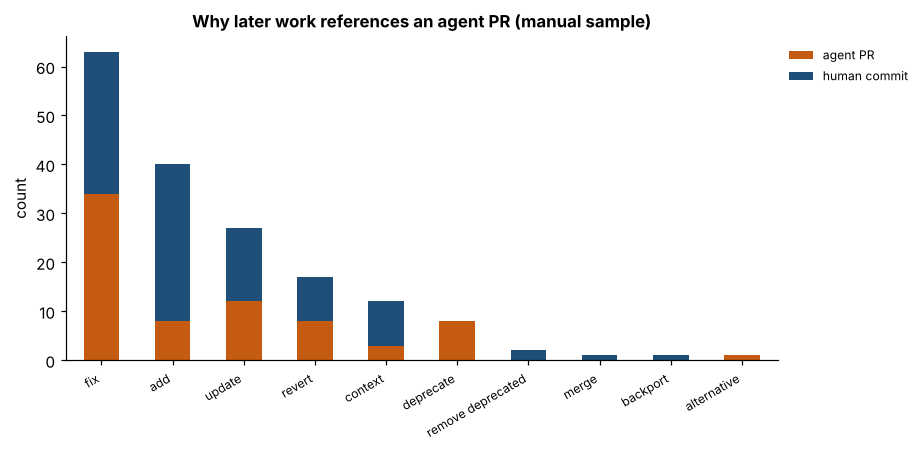

*Exact numbers – Why later work references an agent PR (manual sample)*

src,agent PR,human commit,TOTAL
type,,,
alternative,1,0,1
backport,0,1,1
merge,0,1,1
remove deprecated,0,2,2
deprecate,8,0,8
context,3,9,12
revert,8,9,17
update,12,15,27
add,8,32,40


In [10]:
lab = pd.concat([mh["type"].rename("type").to_frame().assign(src="human commit"), ma["type"].rename("type").to_frame().assign(src="agent PR")], ignore_index=True)
stacked(pd.crosstab(lab["type"], lab["src"]).loc[lambda t: t.sum(axis=1).sort_values().index], "Why later work references an agent PR (manual sample)", "1_reference_types.png", colors=[ORANGE, BLUE])

### Chart 2 · Fix references per AI agent

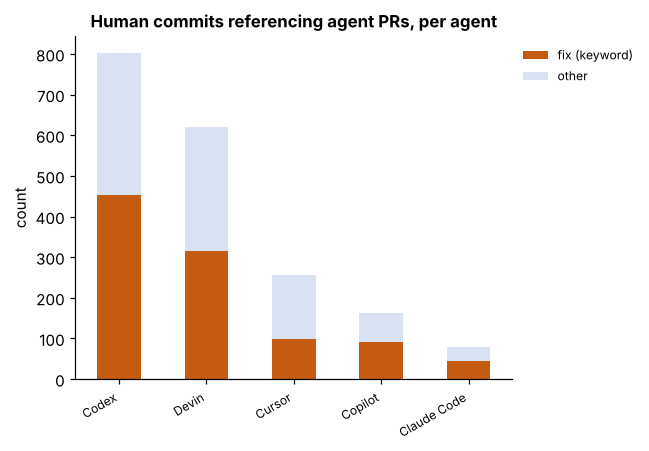

*Exact numbers – Human commits referencing agent PRs, per agent*

,fix (keyword),other,TOTAL
agent,,,
Claude Code,44,36,80
Copilot,91,71,162
Cursor,99,158,257
Devin,316,304,620
Codex,454,349,803
TOTAL,1004,918,1922


In [11]:
stacked(pd.DataFrame({"fix (keyword)": per_agent["fix_refs"], "other": per_agent["human_refs"] - per_agent["fix_refs"]}).iloc[::-1], "Human commits referencing agent PRs, per agent", "2_fix_refs_per_agent.png", colors=[ORANGE, LIGHT])

### Chart 3 · Who wrote the referencing commit

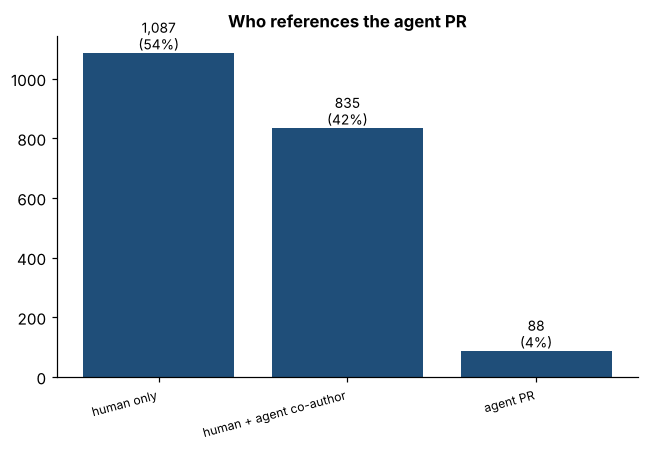

*Exact numbers – Who references the agent PR*

,number,%
human only,1087.0,54.1
human + agent co-author,835.0,41.5
agent PR,88.0,4.4
TOTAL,2010.0,100.0


In [12]:
who = pd.Series({"human only": int(h.source_commit_co_author.isna().sum()), "human + agent co-author": int(h.source_commit_co_author.notna().sum()), "agent PR": len(a)})
bar(who, "Who references the agent PR", "3_who_references.png", pct=True)

### Chart 4 · How long after the agent PR

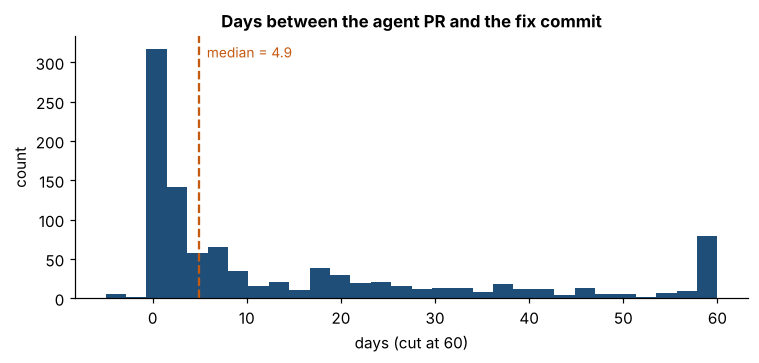

*Exact numbers – Days between the agent PR and the fix commit*

,count,mean,std,min,25%,median,75%,max
days (cut at 60),1004.0,14.7,19.11,-5.0,0.66,4.93,22.86,60.0


In [13]:
hist(h.loc[h.is_fix, "days_after_pr"].clip(-5, 60), "Days between the agent PR and the fix commit", "4_days_to_fix.png", "days (cut at 60)", bins=30)

## 4. Final figure

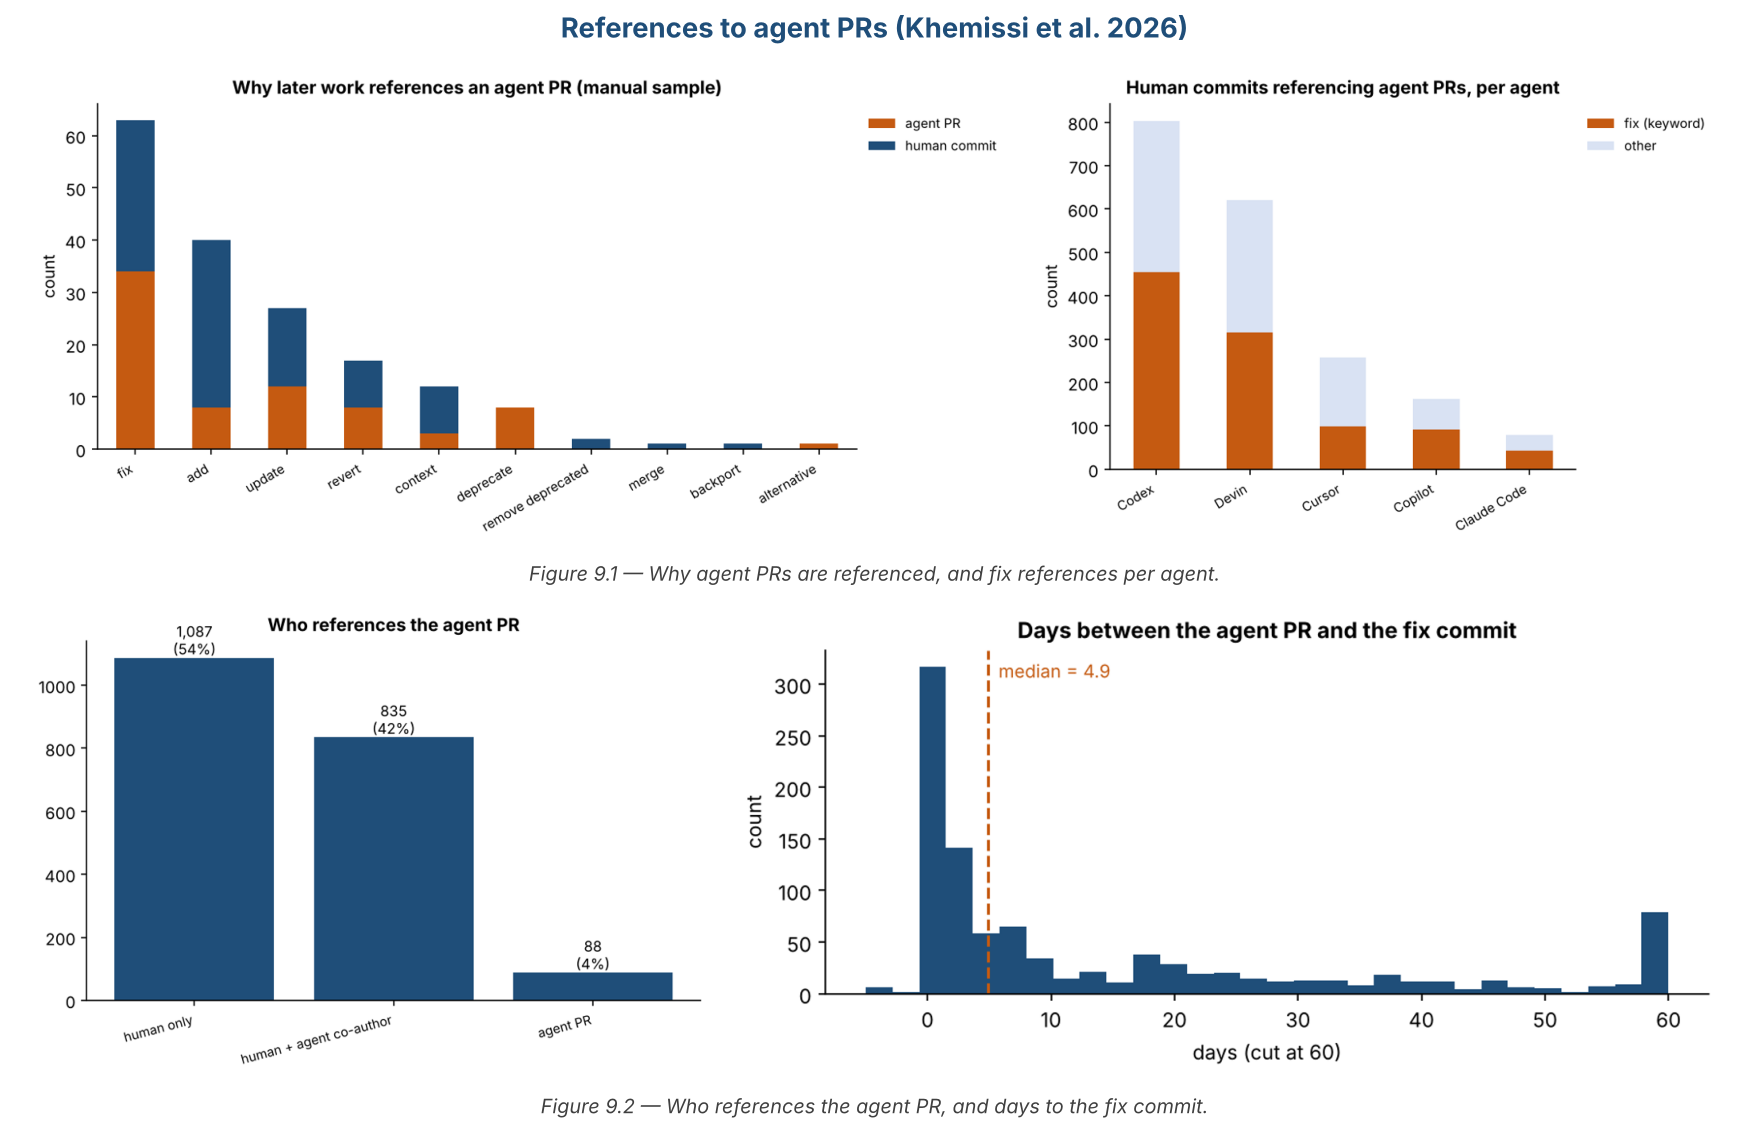

In [14]:
final_figure(9, "References to agent PRs (Khemissi et al. 2026)",
             "Why agent PRs are referenced, and fix references per agent.",
             "Who references the agent PR, and days to the fix commit.")

## 5. The fixes in one common format
Each row = one **later commit (human) or PR (agent) that references an agent PR and looks like a fix** (keyword in the message/title), with its **code patch** when available. Manual label kept when the commit is in the hand-labelled sample.

In [15]:
hm = dict(zip(mh["Source Commit URL"].str.rstrip("/").str.split("/").str[-1], mh["type"]))
hf = h[h.is_fix].drop_duplicates(["target_pr_html_url", "source_commit_sha"])
repo = hf["target_pr_html_url"].str.extract(r"github\.com/([^/]+/[^/]+)")[0]
f1 = pd.DataFrame({"agent": hf["agent"], "repo": repo, "language": hf["source_commit_filename"].fillna("").map(lang_of), "level": "commit",
    "ai_change": hf["target_pr_html_url"], "fix_change": hf["source_commit_sha"],
    "fixed_by": hf["source_commit_co_author"].notna().map({True: "AI agent", False: "Human"}), "days_to_fix": hf["days_after_pr"].round(2),
    "fix_label": hf["source_commit_sha"].map(hm).fillna("fix keyword").radd("reference: "), "fix_reason": hf["source_commit_message"].astype(str).str.split("\n").str[0],
    "has_code_patch": hf["source_commit_patch"].notna()})
af = a[a.is_fix].drop_duplicates(["target_pr_html_url", "source_pr_html_url"])
f2 = pd.DataFrame({"agent": af["agent"], "repo": af["target_pr_html_url"].str.extract(r"github\.com/([^/]+/[^/]+)")[0], "language": None, "level": "PR",
    "ai_change": af["target_pr_html_url"], "fix_change": af["source_pr_html_url"], "fixed_by": "AI agent", "days_to_fix": af["days_after_pr"].round(2),
    "fix_label": "reference: fix keyword (agent PR)", "fix_reason": af["source_pr_title"], "has_code_patch": False})
fixes = save_fixes(pd.concat([f1, f2], ignore_index=True), "Khemissi 2026")
pat = hf[hf.source_commit_patch.notna()][["source_commit_sha", "source_commit_filename", "source_commit_patch"]]
pat.to_csv(os.path.join("tables", "fix_patches.csv"), index=False); print("patches saved:", len(pat))

**1,032 fixes saved to `tables/fixes.csv`** (same columns in every paper)

,paper,fix_id,agent,repo,language,level,ai_change,fix_change,fixed_by,days_to_fix,fix_label,fix_reason,has_code_patch
0,Khemissi 2026,KHE-00000,Claude Code,ryoppippi/ccusage,TypeScript,commit,https://github.com/ryoppippi/ccusage/pull/128,c2e44b65d379e9de5ac65bc758b35be1283f03ec,Human,1.47,reference: fix keyword,Merge pull request #128 from zhiyue/fix/offline-flag-blo...,True
1,Khemissi 2026,KHE-00001,Claude Code,graphistry/pygraphistry,Python,commit,https://github.com/graphistry/pygraphistry/pull/706,702599939f392c41a38a3a4aea7af276fabab159,AI agent,5.06,reference: fix,fix(rebase): update ASTQueryDAG references to ASTLet aft...,True
2,Khemissi 2026,KHE-00002,Claude Code,sugyan/claude-code-webui,Other,commit,https://github.com/sugyan/claude-code-webui/pull/80,c34450b5fabfb832ca88c6cb711397308ee23f70,AI agent,11.45,reference: fix keyword,fix: replace FedericoCarboni/setup-ffmpeg with apt-get i...,True
3,Khemissi 2026,KHE-00003,Claude Code,dotCMS/core,Other,commit,https://github.com/dotCMS/core/pull/32657,a819a4512061af8f21a50c89c2810044136489c6,AI agent,9.38,reference: add,chore(swagger): Add Swagger annotations Batch Testing Ba...,True
4,Khemissi 2026,KHE-00004,Claude Code,dotCMS/core,Other,commit,https://github.com/dotCMS/core/pull/32663,a819a4512061af8f21a50c89c2810044136489c6,AI agent,9.37,reference: add,chore(swagger): Add Swagger annotations Batch Testing Ba...,True


patches saved: 937
